# E71: Does the least-squares split of a broad fine-tune pass the adversarial check?

## The answer

Least squares fails the check on the full-matrix Adam fine-tune and passes on the rank-8 LoRA, from one attacker start. We predicted that it would fail on both. The LoRA's pass is thin, and it still leaves 38% of the update outside the subcomponents. The LoRA's expressible part keeps most of the gain, leaves that residual alone and passes at the same start. Why the two fine-tunes differ is not established.

*Independently checked, no bug found: `~/commute-data/scratch/commute-lead/e71-check/check.md`. Report: `reports/analyses/2026-11-03_analysis_e71-scorecard-ls.md`.*


## What we were trying to test

The Q1 slide scores ways of carrying a finished update onto the decomposition, on a broad task: a fine-tune that makes the model write lowercase text. Its least-squares row was empty. This run fills it, with the same check as the slide's other rows.

The symbols, per weight matrix:

- $W_0 = U V^\top + \Delta$ is the unchanged model, with $U$ and $V$ the alive subcomponents' write and read vectors.
- $\delta W$ is the fine-tune's weight change.
- $(dU, dV)$ is the **least-squares split**: the least-norm change with $dU V^\top + U dV^\top \approx \delta W$.
- $O(\delta W) = (I - P_U)\,\delta W\,(I - P_V)$ is the remainder the split cannot reach.

**The check** is the adversarial ratio. An attacker searches over masks of the subcomponents to push the output away from the target weights, on 256 Pile rows. The ratio is its KL at a state over its KL at the unchanged model, so the unchanged model reads 1. At or under 1.40 passes, and at or over 1.61 fails. One attacker start was used.

**The fine-tunes** are a full-matrix Adam fine-tune and a rank-8 LoRA, saved files of 300 steps with similar gains.

The states, and what each rules out:

- **Do-nothing** puts all of $\delta W$ in Δ. It must fail, or a pass elsewhere means nothing.
- **The scaled adjoint split** must pass. Its weights differ from the fine-tune's and Δ does not move.
- **The least-squares split** has the fine-tune's own weights, with the subcomponents moved by $(dU, dV)$. So its behaviour kept is 1 by construction.
- **The expressible part**, a name used here, is the update without its remainder, with the same moved subcomponents.

"The expressible part, Δ fixed" has two exact readings, and both were read. Target $W_0 + \delta W - O(\delta W)$ moves Δ by the second-order term $-dU\,dV^\top$. Target $W_0 + (U + dU)(V + dV)^\top - U V^\top$ does not move Δ at all.

Beside the check we read two counts. **Behaviour kept** is the share of the fine-tune's held-out gain that the target weights keep: 0 is the unchanged model, and 1 is the fine-tune. **Left in Δ** is the squared change in Δ over the squared size of the update.


## What we expected, and why

We expected least squares to fail the check on both fine-tunes and to read above do-nothing, because it did both on the emoticon Adam fine-tune. That prior left out the same run's LoRA rows on emoticon, which read low, so the prediction overlooked a precedent.

We expected at least 30% of the update to stay in Δ, as on emoticon. We expected the expressible part to keep more of the gain than the adjoint split. We guessed, with no prior, that the expressible part alone would also fail, since it uses the same moved subcomponents as the least-squares state.


In [1]:
import json
from pathlib import Path
from IPython.display import Image, display, Markdown

ROOT = Path("../experiments/scorecard_ls")
RUN = json.loads((ROOT / "results" / "reads.json").read_text())
PRED = json.loads((ROOT / "results" / "predictions.json").read_text())
R, FIG = RUN["reads"], ROOT / "figures"
FT = (("adam", "Adam"), ("lora", "LoRA"))
STATES = (("nothing", "do-nothing"), ("ls", "least squares"), ("expr", "expressible, second-order term in Δ"),
          ("expr_fixed", "expressible, Δ fixed"), ("adjoint", "scaled adjoint"))

def show(name):
    display(Image(filename=str(FIG / name), width=760))

lines = ["| fine-tune | state | check | kept | left in Δ |", "|---|---|---|---|---|"]
for ft, label in FT:
    for st, name in STATES:
        r = R[f"{st}_{ft}"]
        lines.append(f"| {label} | {name} | {r['check']:.2f} {r['verdict']} | {r['s']:.2f} | {r['delta_share']:.3f} |")
display(Markdown("\n".join(lines)))


| fine-tune | state | check | kept | left in Δ |
|---|---|---|---|---|
| Adam | do-nothing | 4.79 fail | 1.00 | 1.000 |
| Adam | least squares | 12.34 fail | 1.00 | 0.358 |
| Adam | expressible, second-order term in Δ | 6.85 fail | 1.11 | 0.001 |
| Adam | expressible, Δ fixed | 8.25 fail | 1.11 | 0.000 |
| Adam | scaled adjoint | 1.06 pass | 0.81 | 0.000 |
| LoRA | do-nothing | 2.59 fail | 1.00 | 1.000 |
| LoRA | least squares | 1.23 pass | 1.00 | 0.376 |
| LoRA | expressible, second-order term in Δ | 1.14 pass | 0.93 | 0.000 |
| LoRA | expressible, Δ fixed | 1.14 pass | 0.93 | 0.000 |
| LoRA | scaled adjoint | 0.94 pass | 0.67 | 0.000 |

## What we observed

### Does the least-squares split pass the check?


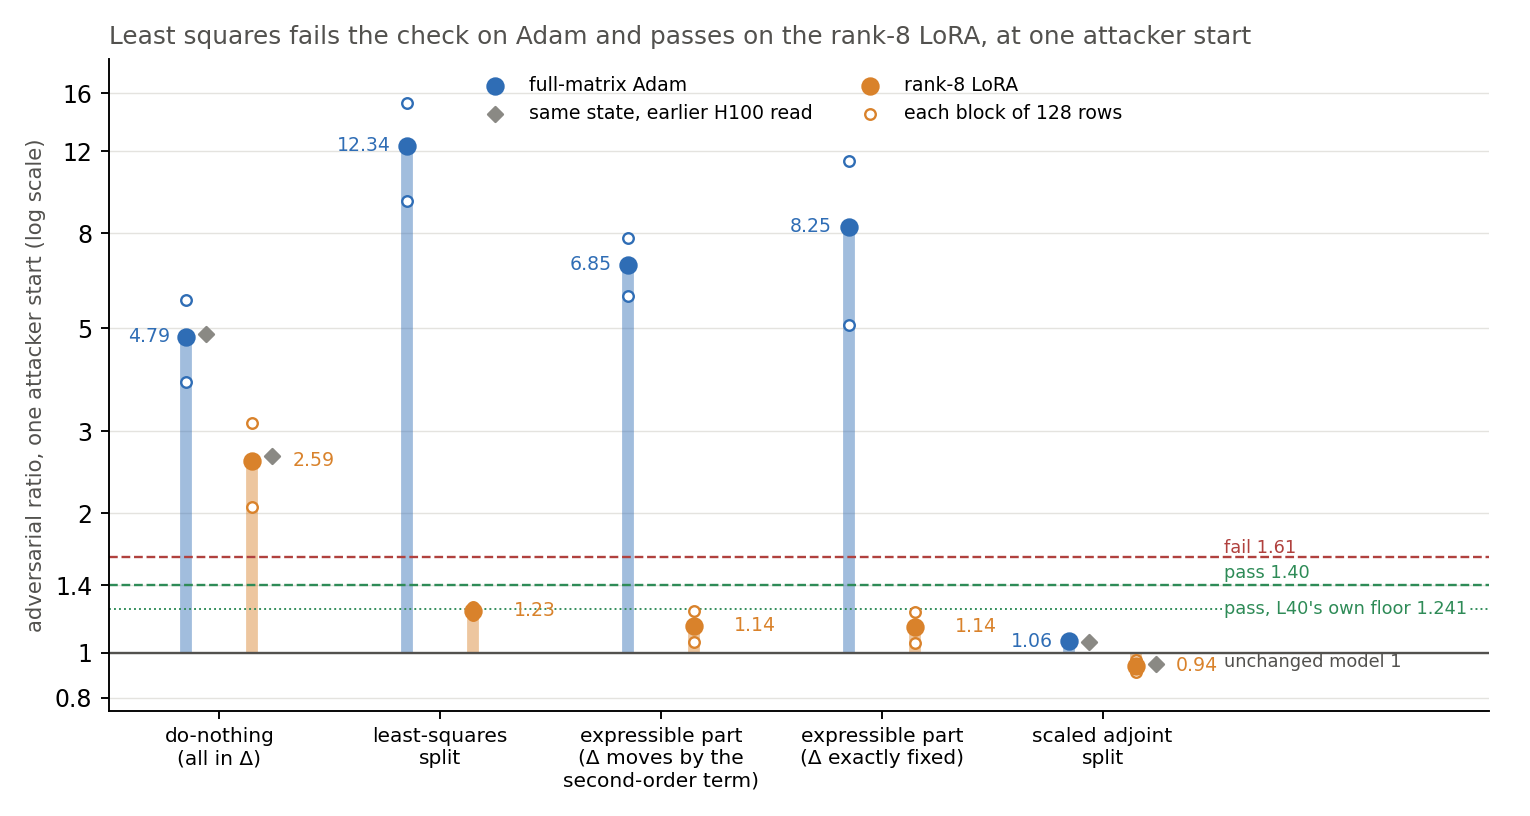

In [2]:
show("check.png")

**Reading it.** No on Adam and yes on the rank-8 LoRA, each from one attacker start. Adam's least squares reads far over the fail line, and the LoRA's sits under the pass line and below its own do-nothing. Do-nothing failed and the adjoint split passed on both fine-tunes, within 2.3% of their earlier H100 readings, so the apparatus is not the explanation.

The LoRA's pass is real, because the same code fails on Adam, but it is thin. It sits 12% under the filed line of 1.40. It sits under 1% below 1.241, the pass line measured for these rows on this card. An earlier teacher-trained rank-8 LoRA moved by about that much between two starts on the same rows.

Adam's order of least squares over do-nothing holds on both blocks, at one start. Another attacker start once took a do-nothing state from 1.6 to 9.2, so that order is unsettled.

### Does the expressible part alone pass, and does it keep the behaviour?


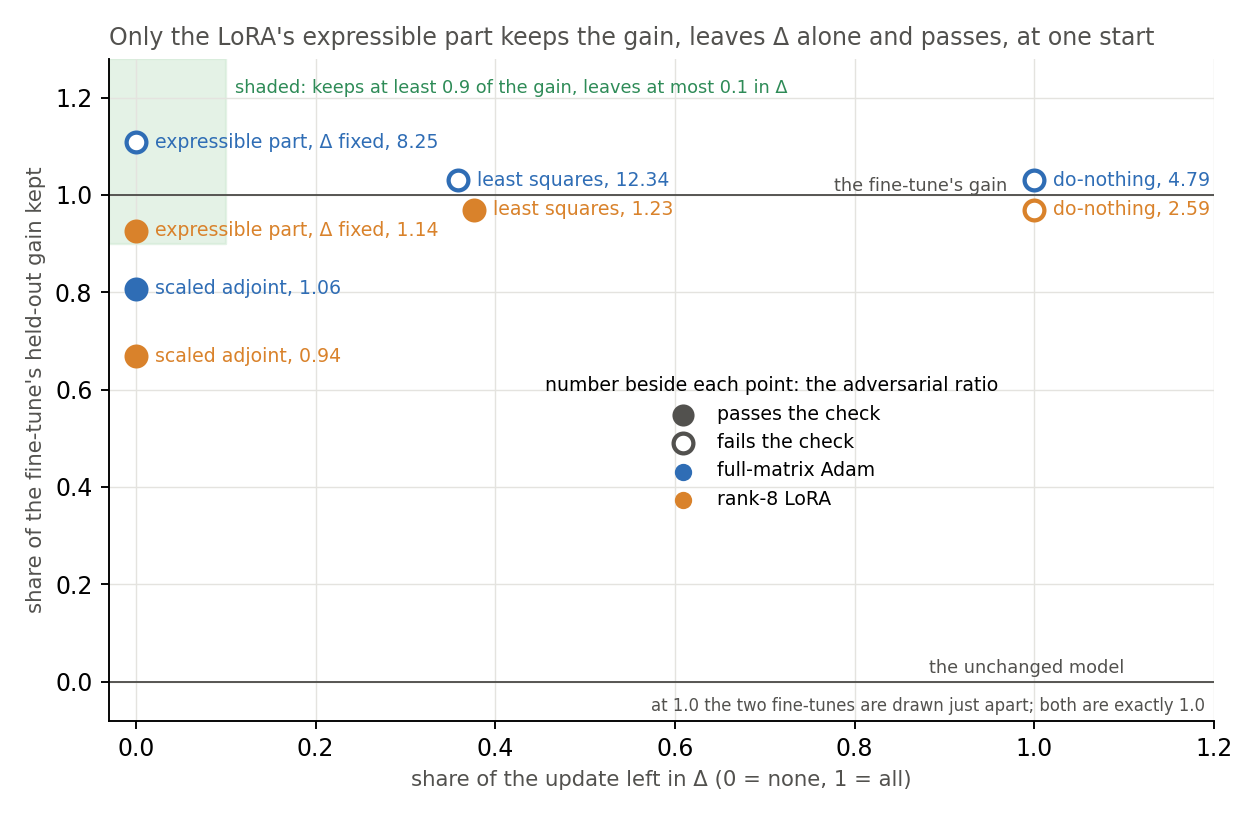

In [3]:
show("keep_delta.png")

**Reading it.** On the rank-8 LoRA yes at this one start, and on Adam no. The LoRA's expressible part keeps 0.93 of the gain, barely moves Δ and reads 1.14. That beats the adjoint split's 0.67 on behaviour, at the same near-zero share in Δ. On Adam it fails with Δ fixed, so Adam's fail does not need the remainder in Δ.

The two readings on Adam, 6.85 and 8.25, are probably attacker noise rather than an effect of the second-order term. Their order flips between the two blocks, seen in the first figure's hollow dots, and every other reading of the pair agrees within 0.5%. No cause is established.

Adam's 1.11 is share of gain read on the target weights, with no masks, on 64 rows. So it is not a claim about the subcomponents. An earlier reading on this task reached 1.04.

Why the LoRA and Adam differ is not established. The share outside the subcomponents sits near its random null on both. Cancellation among the moved subcomponents is alike. The update's norm differs 1.6 times and its rank is 8 against 768, while the check's excess over 1 differs about 49 times.


## What we learned

Least squares does not meet the weak version in `GOALS.md` on either fine-tune, because Δ absorbs over a third of the update, whatever a further start reads. The check's verdict depends on the fine-tune here, as it did for teacher training on the same two. The new thing is the LoRA's expressible part: a one-shot formula that writes most of a broad LoRA's effect onto the subcomponents and passes at one start. Its weights are not the fine-tune's, since they drop the remainder. On Adam the same formula fails, so it is not a general answer.

## How compelling is the evidence

Weak on anything that depends on the start. Every state has one attacker start on 256 rows, so a state that fails elsewhere reads as a pass. The filed lines come from the H100, and this card's spread between starts is about three times larger. Left in Δ counts all weight directions alike. One decomposition, one task and one seed of each fine-tune were read. An independent check traced the code and recomputed the Δ numbers on CPU, finding no bug, but it re-read nothing on a GPU.

## Surprises

**Something unexpected happened that I cannot explain.** We predicted three things on both fine-tunes: least squares fails, it reads above do-nothing, and the expressible part fails. On the rank-8 LoRA all three reversed, and on Adam all three held. The predictions stand as filed.

Adam's expressible part keeps more than the fine-tune's gain, for a reason we did not establish. The job took 25 minutes against the plan's 12.

## What next

1. Re-read the LoRA's least squares and expressible part from other starts and new rows. If they stay under the line, the cell and that lead stand. If not, the cell changes and the lead closes.
2. Read Adam's least squares scaled to the LoRA's size, and cut to rank 8. If one falls to the LoRA's range, that names size or rank as the reason.
3. Or run nothing, since the 67M runs only when the user asks. Both options, with an estimate, wait in the research log's decision card and the report.

## Scorecard


In [4]:
def call(v, hold, refute):
    return "holds" if hold(v) else "refuted" if refute(v) else "no call"

ls = lambda ft: R[f"ls_{ft}"]
passes, fails = PRED["lines"]["pass"], PRED["lines"]["fail"]
fail_rule = lambda v: call(v, lambda x: x >= fails, lambda x: x <= passes)
rows = {
    "P1": ("Least squares fails the check", "at or over 1.61 holds; at or under 1.40 refuted", lambda ft: [(ls(ft)["check"], fail_rule(ls(ft)["check"]))]),
    "P2": ("Least squares reads above do-nothing", "ratio over 1.075 holds; under 1/1.075 refuted",
           lambda ft: [(v := ls(ft)["check"] / R[f"nothing_{ft}"]["check"], call(v, lambda x: x > 1.075, lambda x: x < 1 / 1.075))]),
    "P3": ("Least squares leaves at least 30% in Δ", "at or over 0.30 holds", lambda ft: [(v := ls(ft)["delta_share"], "holds" if v >= 0.30 else "refuted")]),
    "P4": ("The expressible part keeps more than the adjoint split", "each reading: difference over 0.02 holds; under -0.02 refuted",
           lambda ft: [(v := R[f"{e}_{ft}"]["s"] - R[f"adjoint_{ft}"]["s"], call(v, lambda x: x > 0.02, lambda x: x < -0.02)) for e in ("expr", "expr_fixed")]),
    "P5": ("The expressible part alone fails the check", "each reading: at or over 1.61 holds; at or under 1.40 refuted",
           lambda ft: [(R[f"{e}_{ft}"]["check"], fail_rule(R[f"{e}_{ft}"]["check"])) for e in ("expr", "expr_fixed")]),
}
lines = ["| id | claim | rule | Adam | LoRA |", "|---|---|---|---|---|"]
for pid, (claim, rule, read) in rows.items():
    cells = [", ".join(f"{v:.3f} {c}" for v, c in read(ft)) for ft, _ in FT]
    lines.append(f"| {pid} | {claim} | {rule} | {cells[0]} | {cells[1]} |")
display(Markdown("\n".join(lines)))


| id | claim | rule | Adam | LoRA |
|---|---|---|---|---|
| P1 | Least squares fails the check | at or over 1.61 holds; at or under 1.40 refuted | 12.340 holds | 1.232 refuted |
| P2 | Least squares reads above do-nothing | ratio over 1.075 holds; under 1/1.075 refuted | 2.574 holds | 0.475 refuted |
| P3 | Least squares leaves at least 30% in Δ | at or over 0.30 holds | 0.358 holds | 0.376 holds |
| P4 | The expressible part keeps more than the adjoint split | each reading: difference over 0.02 holds; under -0.02 refuted | 0.303 holds, 0.301 holds | 0.258 holds, 0.258 holds |
| P5 | The expressible part alone fails the check | each reading: at or over 1.61 holds; at or under 1.40 refuted | 6.848 holds, 8.253 holds | 1.143 refuted, 1.138 refuted |

## Not run

Any other attacker start, including the budget start. Rows 256-511 or other Pile rows. Adam's least squares scaled to the LoRA's size or cut to rank 8. The input-weighted size of the second-order term. A repeat of a control at the job's end. Any fp32 or H100 re-read. A second seed of either fine-tune, or another task.

## Departures from the literature

The adversary is the VPD authors' multi-batch masked reconstruction loss under bf16 autocast, at their 128-row scope. The ratio and its lines are this project's. Reading Γ on updated weights with Γ frozen, the splits and the expressible part are this project's operations.

## Provenance

`experiments/scorecard_ls/results/{reads.json,run.log,predictions.json}`, `experiments/scorecard_ls/figures/{check,keep_delta}.png`. Inputs: `experiments/row_blocks/results/large/dW_{adam,lora}.pt`, hashes checked. MATS cluster, NVIDIA L40, `debug` QoS, job 50287, 25 minutes, $0.
